In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import *
import time 

In [2]:
N = 1024
dx = 0.1
x = np.arange(-N/2, N/2)*dx
L = N*dx

dxi = (2*np.pi)/(N*dx)
xi = np.arange(-N/2, N/2)*dxi
W = N*dxi      

In [3]:
a = 2

In [6]:
# Analytical
fa = np.exp(-a*np.abs(x))
Fa = 2*a / ((a**2) + (xi**2))

In [8]:
# Numerical (FFT)
start = time.process_time()
FFTn = fftshift(fft(ifftshift(fa)))*dx
IFFTn = fftshift(ifft(ifftshift(Fa)))/dx
end = time.process_time()

print(end - start)

0.001454999999999984


In [9]:
# Numerical (DFT)
start = time.process_time()
DFTn = []
IDFTn = []
for t in range(N):
    DFTn.append(sum(fa*np.exp(-xi[t]*1j*x)*dx))
    IDFTn.append(sum(Fa*np.exp(xi[t]*1j*x)*dxi) / (2*np.pi))
end = time.process_time()

print(end - start)

0.18806199999999995


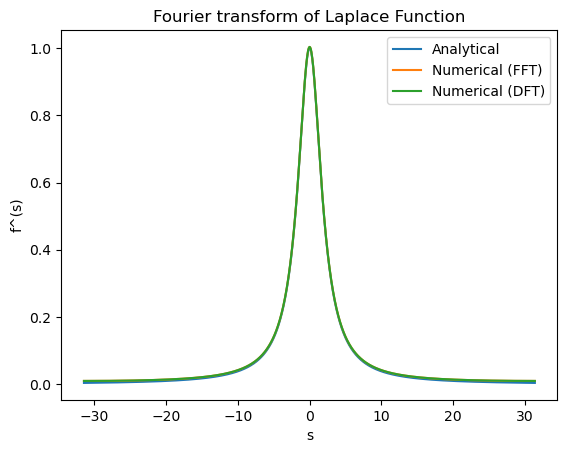

In [10]:
plt.figure(1)
plt.plot(xi, Fa, label='Analytical')
plt.plot(xi, FFTn.real, label='Numerical (FFT)')
plt.plot(xi, np.real(DFTn), label='Numerical (DFT)')
plt.xlabel('s')
plt.ylabel('f^(s)')
plt.title('Fourier transform of Laplace Function')
plt.legend()
plt.show()

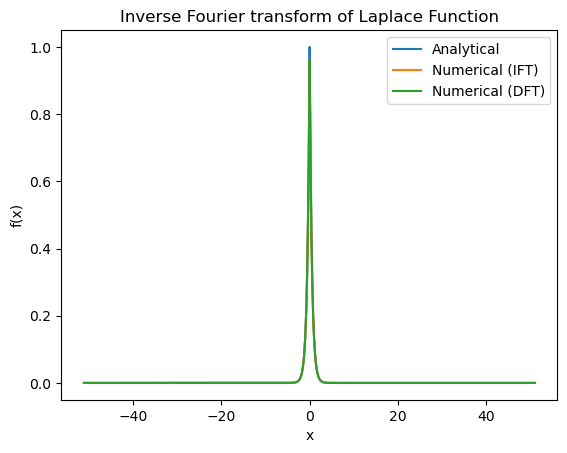

In [11]:
plt.plot(x, fa, label='Analytical')
plt.plot(x, IFFTn.real, label='Numerical (IFT)')
plt.plot(x, np.real(IDFTn), label='Numerical (DFT)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Inverse Fourier transform of Laplace Function')
plt.legend()
plt.show()